# 01 - Prepare GAN data (HAM10000, lesion-level split v2)

**Mục đích:** chuẩn bị dữ liệu cho GAN từ manifest đã chốt.

1. Kiểm tra `HAM10000_lesion_split_seed42_v2.csv` (SHA-256, số dòng, 0 lesion trùng giữa các split).
2. Cắt vuông ở giữa + resize toàn bộ 10,015 ảnh về `RESxRES` PNG -> `real_sq256/`
   (để notebook classifier dùng cùng tiền xử lý cho ảnh thật và ảnh GAN).
3. Đóng gói chỉ split `train` thành `gan_train.zip` + `dataset.json` (định dạng StyleGAN2/3, có nhãn lớp).

**Input:** dataset `DSR301m` của nhóm (chứa cả `dataset/dataset/ISIC2018_Task3_Training_Input/`
và `HAM10000_lesion_split_seed42_v2.csv`). Notebook tự tìm đúng thư mục ảnh train và file manifest.

**Output (`/kaggle/working`):** dùng làm input cho notebook 02, 03 và classifier:
```
real_sq256/ISIC_xxxxxxx.png      # 10,015 ảnh, mọi split
gan_train.zip                    # chỉ split train + dataset.json
gan_train_manifest.csv           # image_id, lesion_id, dx, class_idx, zip_path
class_map.json                   # thứ tự lớp <-> chỉ số nhãn GAN
prep_info.json                   # hash, số lượng, cấu hình
preview_grid.png
```

In [1]:
import os, glob, json, hashlib, zipfile, time
import numpy as np
import pandas as pd
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

# ===== CONFIG =====
SPLIT_CSV_NAME  = "HAM10000_lesion_split_seed42_v2.csv"
TRAIN_IMG_DIR_NAME = "ISIC2018_Task3_Training_Input"   # thư mục chứa 10,015 ảnh HAM10000
EXPECTED_SHA256 = "5d9d87934b2a8368eb23ef68254edecb87ab31230cdc8b0273d3eb8221354273"
RES       = 256                      # độ phân giải GAN (lũy thừa của 2)
CLASSES   = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]   # thứ tự CỐ ĐỊNH -> chỉ số nhãn
INPUT_ROOT = "/kaggle/input"
OUT        = "/kaggle/working"
REAL_DIR   = os.path.join(OUT, f"real_sq{RES}")
N_WORKERS  = 8
os.makedirs(REAL_DIR, exist_ok=True)

## 1. Tìm file input

In [ ]:
def find_files(pattern):
    return sorted(glob.glob(os.path.join(INPUT_ROOT, "**", pattern), recursive=True))

hits = find_files(SPLIT_CSV_NAME)
assert hits, f"Không tìm thấy {SPLIT_CSV_NAME} trong {INPUT_ROOT}. Hãy Add Input dataset chứa file này."
split_path = hits[0]
print("Manifest:", split_path)

# Chỉ mục ảnh: image_id -> đường dẫn. Ưu tiên thư mục ảnh train của ISIC 2018 Task 3
train_dirs = [d for d in find_files(TRAIN_IMG_DIR_NAME) if os.path.isdir(d)]
search = [os.path.join(train_dirs[0], "ISIC_*.jpg")] if train_dirs else [os.path.join(INPUT_ROOT, "**", "ISIC_*.jpg")]
print("Tìm ảnh trong:", search[0])
img_index = {}
for p in sorted(glob.glob(search[0], recursive=True)):
    img_index.setdefault(os.path.splitext(os.path.basename(p))[0], p)
print(f"Tìm thấy {len(img_index):,} file ảnh ISIC_*.jpg")

Manifest: /kaggle/input/datasets/bumkum/dsr301m/HAM10000_lesion_split_seed42_v2.csv
Tìm ảnh trong: /kaggle/input/datasets/bumkum/dsr301m/dataset/dataset/ISIC2018_Task3_Training_Input/ISIC_*.jpg
Tìm thấy 10,015 file ảnh ISIC_*.jpg


## 2. Kiểm tra manifest

In [3]:
sha = hashlib.sha256(open(split_path, "rb").read()).hexdigest()
print("SHA-256:", sha)
assert sha == EXPECTED_SHA256, "Manifest KHÁC bản đã chốt! Dừng lại và kiểm tra trước khi đi tiếp."

df = pd.read_csv(split_path)
assert list(df.columns) == ["image_id", "lesion_id", "dx", "split"], df.columns
assert len(df) == 10015 and df.image_id.is_unique
assert set(df.dx) <= set(CLASSES), set(df.dx) - set(CLASSES)
assert df.groupby("lesion_id").dx.nunique().max() == 1, "Có lesion mang >1 chẩn đoán"

lesions = {s: set(g.lesion_id) for s, g in df.groupby("split")}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    n = len(lesions[a] & lesions[b])
    print(f"lesion overlap {a}/{b}: {n}")
    assert n == 0

missing = sorted(set(df.image_id) - set(img_index))
assert not missing, f"Thiếu {len(missing)} ảnh, ví dụ {missing[:5]}"

df["class_idx"] = df.dx.map({c: i for i, c in enumerate(CLASSES)})
print(pd.crosstab(df.split, df.dx, margins=True))

SHA-256: 5d9d87934b2a8368eb23ef68254edecb87ab31230cdc8b0273d3eb8221354273
lesion overlap train/val: 0
lesion overlap train/test: 0
lesion overlap val/test: 0
dx     akiec  bcc   bkl   df   mel    nv  vasc    All
split                                                
test      52   71   167   20   167  1004    21   1502
train    222  361   772   71   773  4683    99   6981
val       53   82   160   24   173  1018    22   1532
All      327  514  1099  115  1113  6705   142  10015


## 3. Cắt vuông + resize toàn bộ ảnh

Ảnh gốc 600x450 -> cắt vùng vuông ở giữa (450x450, tổn thương thường nằm giữa) -> resize `RESxRES` (Lanczos) -> PNG.  
Dùng chung cho mọi split để ảnh thật và ảnh GAN có cùng kích thước và định dạng khi vào classifier.

In [4]:
def center_square(img):
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return img.crop((left, top, left + s, top + s))

def process(image_id):
    dst = os.path.join(REAL_DIR, f"{image_id}.png")
    if not os.path.exists(dst):
        img = Image.open(img_index[image_id]).convert("RGB")
        center_square(img).resize((RES, RES), Image.LANCZOS).save(dst, optimize=False)
    return dst

t0 = time.time()
with ThreadPoolExecutor(N_WORKERS) as ex:
    list(ex.map(process, df.image_id))
print(f"Xong {len(df):,} ảnh trong {time.time() - t0:.0f}s")

sizes = {Image.open(os.path.join(REAL_DIR, f"{i}.png")).size for i in df.image_id.sample(50, random_state=0)}
assert sizes == {(RES, RES)}, sizes

Xong 10,015 ảnh trong 163s


## 4. Đóng gói split train cho GAN

`gan_train.zip` chứa `<dx>/<image_id>.png` và `dataset.json` dạng `{"labels": [["df/ISIC_xxx.png", 3], ...]}` - định dạng mà `train.py --cond=True` của StyleGAN2-ADA / StyleGAN3 đọc trực tiếp.  
**Không có ảnh val/test nào trong zip** (assert bên dưới).

In [5]:
train = df[df.split == "train"].sort_values("image_id").reset_index(drop=True)
train["zip_path"] = train.dx + "/" + train.image_id + ".png"

zip_path = os.path.join(OUT, "gan_train.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_STORED) as zf:   # PNG đã nén sẵn
    for r in train.itertuples():
        zf.write(os.path.join(REAL_DIR, f"{r.image_id}.png"), r.zip_path)
    labels = [[p, int(c)] for p, c in zip(train.zip_path, train.class_idx)]
    zf.writestr("dataset.json", json.dumps({"labels": labels}))

with zipfile.ZipFile(zip_path) as zf:
    names = [n for n in zf.namelist() if n.endswith(".png")]
    ids_in_zip = {os.path.splitext(os.path.basename(n))[0] for n in names}
assert len(names) == len(train) == 6981, len(names)
assert not ids_in_zip & set(df[df.split != "train"].image_id), "LEAKAGE: ảnh val/test trong zip GAN!"
print(f"gan_train.zip: {len(names):,} ảnh, {os.path.getsize(zip_path) / 1e9:.2f} GB")
print(train.dx.value_counts())

gan_train.zip: 6,981 ảnh, 0.67 GB
dx
nv       4683
mel       773
bkl       772
bcc       361
akiec     222
vasc       99
df         71
Name: count, dtype: int64


## 5. Lưu manifest, class map, thông tin tái lập

In [6]:
train[["image_id", "lesion_id", "dx", "class_idx", "zip_path"]].to_csv(
    os.path.join(OUT, "gan_train_manifest.csv"), index=False)
json.dump({c: i for i, c in enumerate(CLASSES)}, open(os.path.join(OUT, "class_map.json"), "w"), indent=2)

def file_sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

info = {
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
    "split_manifest": os.path.basename(split_path),
    "split_manifest_sha256": sha,
    "res": RES, "crop": "center_square", "resample": "LANCZOS", "format": "PNG",
    "classes": CLASSES,
    "n_real_sq_images": int(len(df)),
    "n_gan_train_images": int(len(train)),
    "gan_train_counts": train.dx.value_counts().to_dict(),
    "gan_train_zip_sha256": file_sha(zip_path),
}
json.dump(info, open(os.path.join(OUT, "prep_info.json"), "w"), indent=2)
print(json.dumps(info, indent=2))

{
  "created": "2026-10-19 10:32:06",
  "split_manifest": "HAM10000_lesion_split_seed42_v2.csv",
  "split_manifest_sha256": "5d9d87934b2a8368eb23ef68254edecb87ab31230cdc8b0273d3eb8221354273",
  "res": 256,
  "crop": "center_square",
  "resample": "LANCZOS",
  "format": "PNG",
  "classes": [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc"
  ],
  "n_real_sq_images": 10015,
  "n_gan_train_images": 6981,
  "gan_train_counts": {
    "nv": 4683,
    "mel": 773,
    "bkl": 772,
    "bcc": 361,
    "akiec": 222,
    "vasc": 99,
    "df": 71
  },
  "gan_train_zip_sha256": "488306f8cee3a96de0f888049990778ab7a915dfd93433521180d19a565aa6df"
}


## 6. Xem nhanh 8 ảnh train mỗi lớp

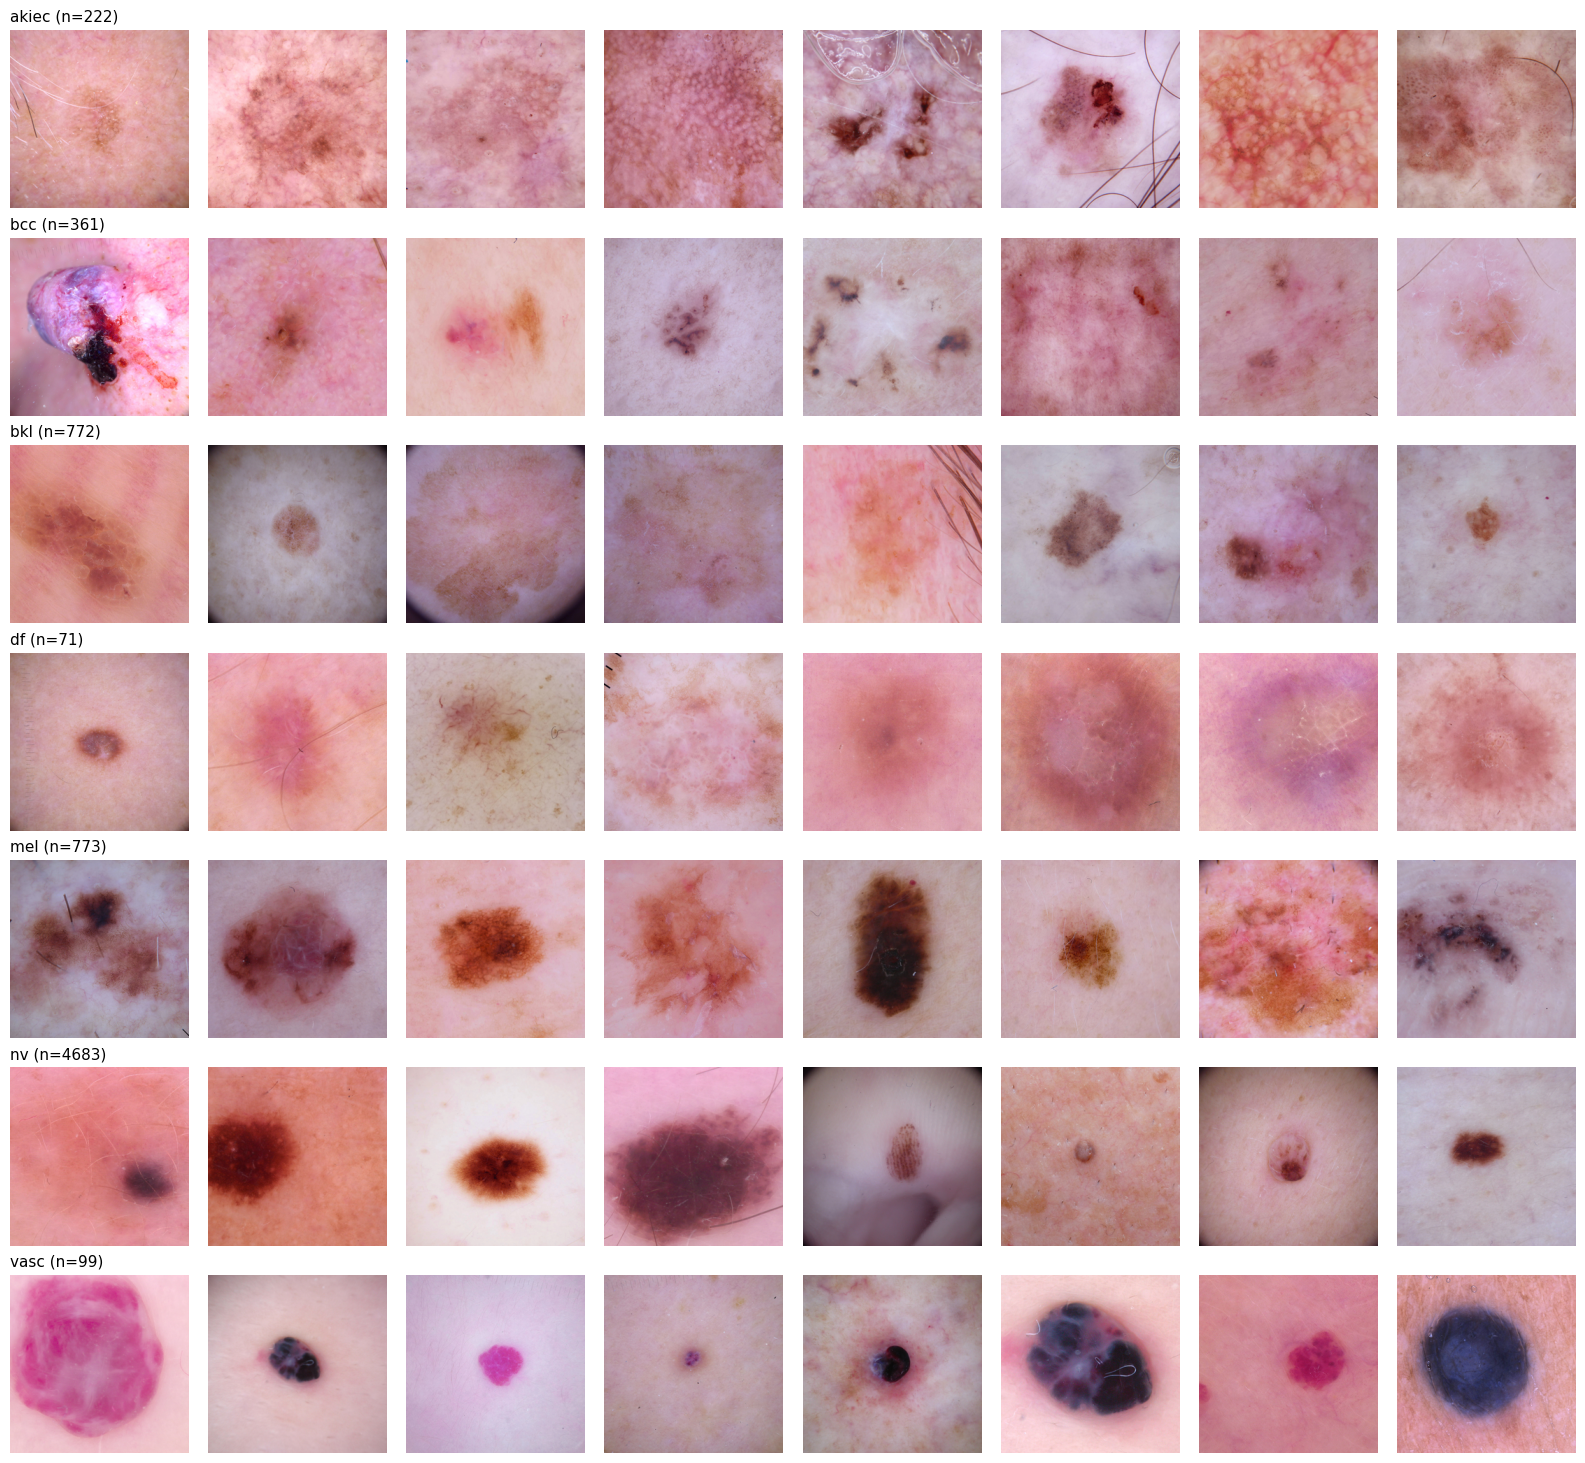

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(CLASSES), 8, figsize=(16, 2.1 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    ids = train[train.dx == c].sample(8, random_state=0).image_id
    for j, iid in enumerate(ids):
        ax = axes[i, j]
        ax.imshow(Image.open(os.path.join(REAL_DIR, f"{iid}.png")))
        ax.axis("off")
        if j == 0:
            ax.set_title(f"{c} (n={int((train.dx == c).sum())})", loc="left", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(OUT, "preview_grid.png"), dpi=80)
plt.show()